In [5]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp
import pandas as pd
from scipy import stats
from scipy.optimize import fsolve

In [6]:

df = pd.read_csv("site_class_index_table.csv")


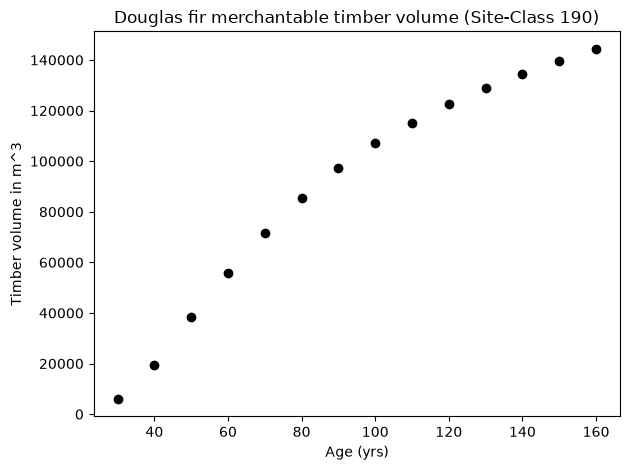

In [7]:
#A1a
df2 = df["190"]
age = df["Age (yrs)"]
plt.scatter(age,df2, color="black")
plt.xlabel("Age (yrs)")
plt.ylabel("Timber volume in m^3")
plt.title("Douglas fir merchantable timber volume (Site-Class 190)")
plt.tight_layout()
plt.show()

![A1b](A1.jpg)

a = 12.6993
b = 114.0496


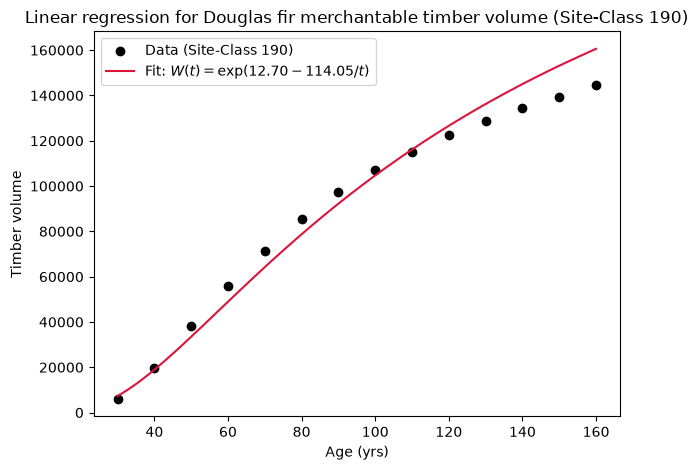

In [8]:
#A1c
#get arrays
t = df["Age (yrs)"]
W = df["190"]

#bring in linear form, -b * 1/t +a
x = 1 / t
#logarithm w
y = np.log(W)

#make linear fit
slope, intercept = np.polyfit(x, y, 1)
a = intercept
#its minus slope bec its -b
b = -slope

print(f"a = {a:.4f}")
print(f"b = {b:.4f}")

#make more t values for a nicer graph
t_fine = np.linspace(30, 160, 500)
#bring linear fit back in exponential form
W_fit = np.exp(a - b / t_fine)

#plot
plt.scatter(t, W, color="black", label="Data (Site-Class 190)")
plt.plot(t_fine, W_fit, color="crimson", label=f"Fit: $W(t) = \\exp({a:.2f} - {b:.2f}/t)$")
plt.xlabel("Age (yrs)")
plt.ylabel("Timber volume")
plt.title("Linear regression for Douglas fir merchantable timber volume (Site-Class 190)")
plt.legend()
plt.tight_layout()
plt.show()

a = -375.6512
b = 27.4599
d = 0.1260


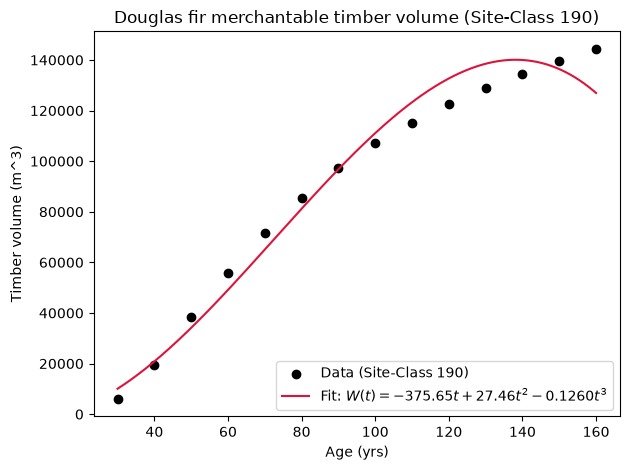

In [9]:
#a2a
t = df["Age (yrs)"]
W = df["190"]

#Dividing by t, to get a constant term
#Using polyft for a quadratic equation, because we divided by t
minus_d, b, a = np.polyfit(t, W / t, 2)
#polyfit return -d as a coefficient, instead of d
d = -minus_d

print(f"a = {a:.4f}")
print(f"b = {b:.4f}")
print(f"d = {d:.4f}")

#make more t values for a nicer graph
t_fine = np.linspace(30, 160, 500)
#cubic volume function
W_fit = a * t_fine + b * t_fine**2 - d * t_fine**3

plt.scatter(t, W, color="black", label="Data (Site-Class 190)")
plt.plot(t_fine, W_fit, color="crimson", label=f"Fit: $W(t) = {a:.2f}t + {b:.2f}t^2 - {d:.4f}t^3$")
plt.xlabel("Age (yrs)")
plt.ylabel("Timber volume (m^3)")
plt.title("Douglas fir merchantable timber volume (Site-Class 190)")
plt.legend()
plt.tight_layout()
plt.show()

![A2](A2b.jpg)

In [10]:
#A2c
t = (b+ np.sqrt(b**2 + 3 * a*d))/(3* d)
print(f"Optimal single harvesting time t*:{t} years")

Optimal single harvesting time t*:138.14466039348537 years


In [11]:

c = 5000
p = 50

def rotational(t, b, c, d, p):
    return b * t**2 - 2 * d * t**3 + c / p


sol = fsolve(rotational, x0=80, args=(b, c, d, p))

print(f"Optimal rotational length t*: {sol[0]} years")

Optimal rotational length t*: 109.03912216694522 years
